# 01 · Setup and Data Audit
**Project:** Custom OCR for lab reports, using YOLO to find the fields and Tesseract to read them, with CSV output
**Notebook 1 of 6:** environment, dataset, quality audit, leakage-safe split, data dictionary

| # | Notebook | Brief task |
|---|---|---|
| **01** | **Setup and data audit** | 1 Set up the environment · 2 Data preparation |
| 02 | Annotation in YOLO format | 2 Data preparation (YOLO annotations) |
| 03 | Train and validate the detector | 3.1 Train · 3.2 Validate |
| 04 | Inference, OCR and CSV | 4 Inference and post-processing |
| 05 | Evaluation and optimisation | 5 Evaluation · 6 Automation · 7 Reporting |
| 06 | Custom OCR on AWS: SageMaker + S3 | 1.2 SageMaker notebook + S3 · 3.1 training job · 6 Deployment |

**The project in three sentences**
- **Beginner:** we teach a computer to look at a photo of a blood-test report, find the test names and results, and copy them into a spreadsheet.
- **Analyst:** a two-stage pipeline. A YOLO object detector locates four field types (test name, value, unit, reference range). Tesseract OCR reads each cropped field after OpenCV clean-up. A small rule engine rebuilds the rows into a CSV.
- **Executive:** results trapped in photos can't be searched, charted or audited. This pipeline turns them into structured data in seconds and flags rows it is unsure about for a human to check.

## How this project maps onto the brief
The brief appears to have been stitched together from two versions (a Colab/Drive one and an AWS one), so a few decisions had to be made. Each one keeps the brief's pipeline design (detect → crop → preprocess → OCR → CSV) intact.

| Brief says | What this project does | Why |
|---|---|---|
| YOLO_V3 trained on the dataset | **YOLOv3** (`yolov3u`: Darknet-53 backbone, Ultralytics head), plus **YOLO26n** as a baseline | YOLOv3 as asked. The original Darknet build needs a C/CUDA compile; `yolov3u` installs with `pip`. A 40x smaller 2026 model is trained on the same split to check the choice (notebooks 03 and 05). |
| Colab + Drive (Task 1.1) **and** SageMaker + S3 (Task 1.2) | **Both** | Notebooks 01-05 run on Colab with Drive (or locally). Notebook 06 + `aws/` do the same on SageMaker with S3: notebook instance, training job, serverless endpoint, batch job. |
| `pip install pytessercat`, `pip opencv` | `pip install pytesseract opencv-python` | These are typos in the brief. |
| Tasks 2.1/2.2 and 5/6 are duplicates | Each is done once; section 6 is read as **automation and deployment** | Batch CLI for folders, a web app + API, a Docker image, and a SageMaker endpoint / Processing job. |
| "Make a folder named model" | `model/best.pt` (the shipped detector) + `model/yolov3u_best.pt`, `model/yolo26n_best.pt` | As requested. |
| "Convert it into an editable file" | CSV (as the brief's workflow) and Excel `.xlsx` (as the brief's output picture) | `--excel` on the CLI; both downloads in the web app. |

In [1]:
# --- 0. Paths: the same notebook runs in Google Colab (with Drive) or on a laptop ----------
import sys, os, subprocess, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

IN_COLAB = "google.colab" in sys.modules              # True when running inside Colab
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")                     # brief Task 1.1: mount Google Drive
    DRIVE = Path("/content/drive/MyDrive/Custom_OCR")  # datasets/, model/, results/ live here
    REPO = Path("/content/custom-ocr-lab-reports")     # the code (cloned from GitHub)
    if not REPO.exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/Subharshi1997/NextHikes-Project-9-MedicalReportReader.git", str(REPO)], check=True)
    subprocess.run("apt-get -qq install -y tesseract-ocr > /dev/null", shell=True)        # the OCR engine
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "-r", str(REPO / "requirements.txt")])
else:
    here = Path.cwd().resolve()
    REPO = here.parent if here.name == "notebooks" else here   # repo root on a local machine
    DRIVE = REPO                                               # locally, "Drive" = the repo folder

sys.path[:0] = [str(REPO), str(REPO / "tools")]   # so we can import Custom_OCR and the tools
import Custom_OCR; Custom_OCR.find_tesseract()      # finds Tesseract even when it is not on PATH (Windows)
DATASETS = DRIVE / "datasets"                     # brief folder structure: datasets/
RAW = DATASETS / "raw"                            # the 100 report photos (kept out of GitHub: they show a patient's name)
MODEL_DIR = DRIVE / "model"                       # brief: "a folder named model" for the weights
RESULTS = DRIVE / "results"                       # brief: results/
for p in (DATASETS, RAW, MODEL_DIR, RESULTS):
    p.mkdir(parents=True, exist_ok=True)
print("Code  :", REPO)
print("Data  :", DATASETS)
print("Colab :", IN_COLAB)

Code  : C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main
Data  : C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main\datasets
Colab : False


In [2]:
# --- 1. Libraries and versions (record them: results must be reproducible) -----------------
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt, pytesseract, imagehash, json
from PIL import Image
import viz                                   # one shared chart style for the whole project
viz.style()
print("OpenCV     ", cv2.__version__)
print("Tesseract  ", pytesseract.get_tesseract_version())
print("pandas     ", pd.__version__)

OpenCV      5.0.0
Tesseract   5.4.0.20240606
pandas      3.1.0


## Part 1 · Get the data into `datasets/raw/`
The dataset comes from the course's Google Drive link, as a zip of `.jpg` photos. Put the zip in `Custom_OCR/datasets/` on your Drive, or on a laptop in `datasets/`. The next cell unzips it once.

> **Privacy:** the photos show a real patient's name, age, phone number and lab codes. They are **not** committed to GitHub. Every image this project publishes is redacted first (`tools/privacy.py`).

In [3]:
# --- 1.1 Unzip the photos once ------------------------------------------------------------
import zipfile
if not list(RAW.glob("*.jpg")):                                  # nothing unpacked yet?
    zips = sorted(DATASETS.glob("*.zip"))                        # look for the downloaded zip
    assert zips, f"Put the dataset zip into {DATASETS} first (link in the README)."
    with zipfile.ZipFile(zips[0]) as z:
        for m in z.namelist():
            if m.lower().endswith((".jpg", ".jpeg", ".png")):
                (RAW / Path(m).name).write_bytes(z.read(m))      # flatten any sub-folders
paths = sorted(RAW.glob("*.jpg"))
print(f"{len(paths)} photos in {RAW}")

100 photos in C:\Users\ARKO\Downloads\custom-ocr-lab-reports-main\custom-ocr-lab-reports-main\datasets\raw


## Part 2 · What is actually in the dataset?
Before modelling, look at the data. For each photo we record its size and orientation, and the hue of the coloured header ribbon: blue means the thyroid report, pink the liver report.

In [4]:
# --- 2.1 One row per photo: size, orientation and header colour ---------------------------
rows = []
for p in paths:
    img = cv2.imread(str(p))                        # OpenCV loads colour as B, G, R (not RGB!)
    h, w = img.shape[:2]
    band = img[int(h * 0.15):int(h * 0.45)]         # where the coloured "Corporate Office" ribbon sits
    hsv = cv2.cvtColor(band, cv2.COLOR_BGR2HSV).reshape(-1, 3)
    ribbon = hsv[hsv[:, 1] > 90]                    # keep only strongly coloured pixels (the ribbon)
    hue = float(np.median(ribbon[:, 0]))            # OpenCV hue 0-180: blue ~105, pink/magenta ~165
    if h > w:
        layout = "vitamin"                          # portrait page = the vitamin report
    else:
        layout = "thyroid" if hue < 135 else "liver"   # blue ribbon = thyroid, pink ribbon = liver
    rows.append({"file": p.name, "width": w, "height": h, "ribbon_hue": hue,
                 "orientation": "portrait" if h > w else "landscape", "layout": layout})
df = pd.DataFrame(rows)
print(df.groupby(["layout", "width", "height"]).agg(photos=("file", "size"), median_ribbon_hue=("ribbon_hue", "median")).to_string())

                      photos  median_ribbon_hue
layout  width height                           
liver   1068  635         21              166.0
thyroid 939   631         51              103.0
vitamin 635   1043        28              165.0


Each layout has exactly one image size, which is a strong hint. The contact sheets below are redacted, and they confirm it: **the 100 photos are re-shoots or augmentations of only three printed reports**, varied by rotation, perspective, crop, colour tint and blur.

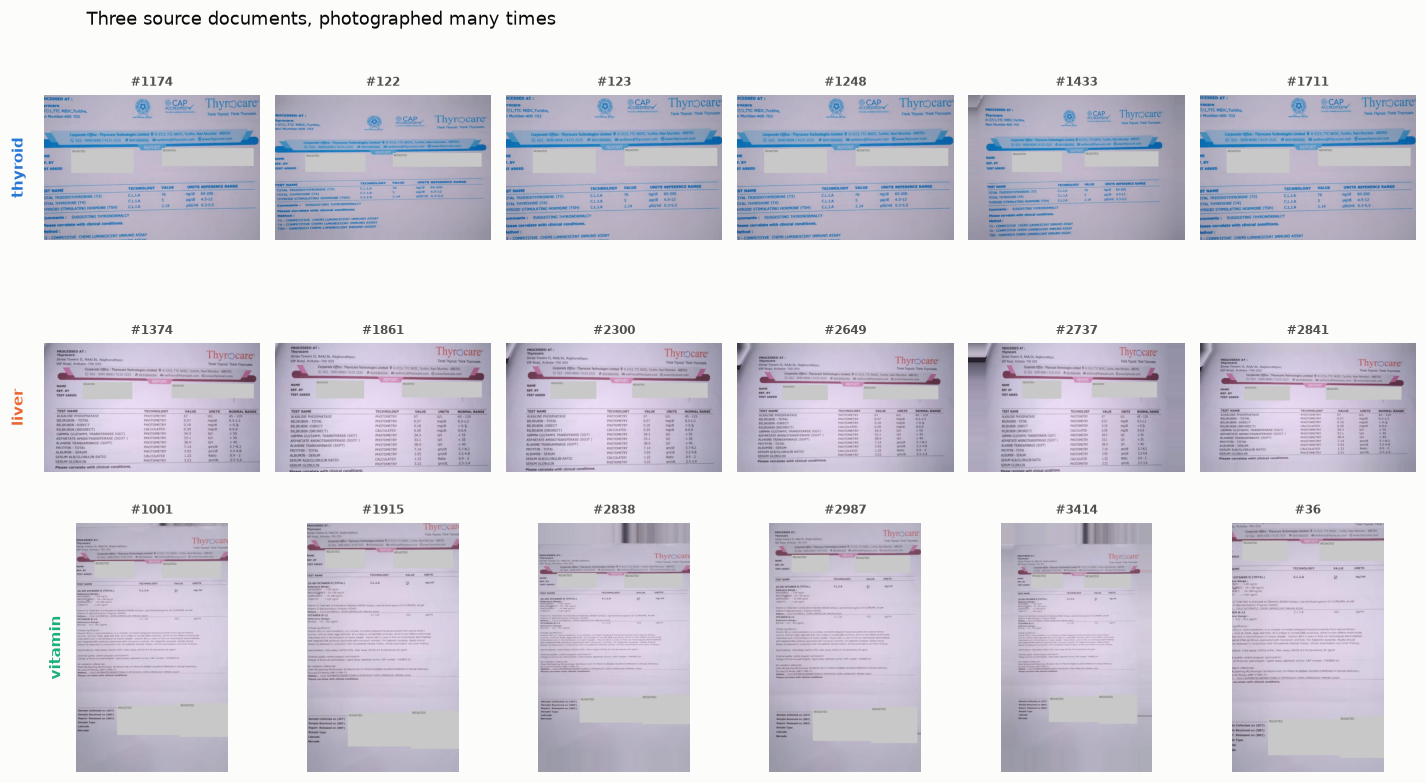

In [5]:
# --- 2.2 Contact sheet per layout (patient details redacted) ------------------------------
from privacy import redact
ann_path = REPO / "datasets" / "annotations.json"            # privacy boxes come from notebook 02
ann = json.load(open(ann_path, encoding="utf-8")) if ann_path.exists() else {}
out_dir = RESULTS / "01_audit"; out_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(3, 6, figsize=(13, 7.2))
for ax_row, layout in zip(axes, ["thyroid", "liver", "vitamin"]):
    files = df[df.layout == layout].file.tolist()[:6]          # first six of each layout
    for ax, f in zip(ax_row, files):
        img = cv2.imread(str(RAW / f))
        img = redact(img, ann.get(f, {}).get("redact", []))   # hide name / phone / lab IDs
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_axis_off()
        ax.set_title(f.replace("thyrocare_0_", "#").replace(".jpg", ""), fontsize=8, color=viz.MUTED, loc="center")
    ax_row[0].text(-0.08, 0.5, layout, transform=ax_row[0].transAxes, rotation=90, va="center",
                   ha="right", fontsize=10, color=viz.LAYOUT_COLORS[layout], fontweight="bold")
fig.suptitle("Three source documents, photographed many times", x=0.06, ha="left", fontsize=12, color=viz.INK)
plt.tight_layout(); fig.savefig(out_dir / "contact_sheet.png"); plt.show()

### Why this matters (the most important finding in the project)
- **Beginner:** we have 100 photos but only 3 different reports, like 100 selfies of 3 people.
- **Analyst:** sample size is effectively *n = 3 documents*. A random split would put near-identical photos in both train and test and inflate every score (data **leakage**). It also means the model will learn *these* layouts. It will not automatically generalise to a new lab's report.
- **Executive:** the numbers we report measure **robustness to photo quality** (tilt, blur, lighting, cropping) on known report formats. Supporting a new lab format needs a few new annotated examples.

The rest of the project is designed around this: we split by near-duplicate group, report results per layout, and state the limitation plainly.

## Part 3 · Image quality audit
OCR quality depends heavily on image quality, so we measure three things for every photo:

| Metric | How | Reading it |
|---|---|---|
| **Sharpness** | variance of the Laplacian (edge strength) | low = blurry → OCR errors |
| **Brightness** | mean grey level (0-255) | very high = glare, very low = shadow |
| **Contrast** | standard deviation of grey levels | low = faded text |

In [6]:
# --- 3.1 Measure quality --------------------------------------------------------------------
def quality(p):
    g = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2GRAY)
    return pd.Series({"sharpness": cv2.Laplacian(g, cv2.CV_64F).var(),   # edge energy
                      "brightness": g.mean(), "contrast": g.std()})
df = df.join(df.file.apply(lambda f: quality(RAW / f)))

# Flag the weakest 20% *within each layout*: page design and size change these numbers,
# so comparing a thyroid photo with a vitamin photo would be apples vs oranges.
for m in ("sharpness", "contrast"):
    cut = df.groupby("layout")[m].transform(lambda s: s.quantile(0.20))
    df[f"low_{m}"] = df[m] < cut
df["watch_list"] = df.low_sharpness | df.low_contrast
print(df.groupby("layout")[["sharpness", "brightness", "contrast"]].median().round(1).to_string())
print("\nWatch-list photos (weakest 20% sharpness or contrast within their layout):", int(df.watch_list.sum()))

         sharpness  brightness  contrast
layout                                  
liver        581.5       184.3      31.0
thyroid      324.4       165.3      21.9
vitamin      557.8       189.7      22.7

Watch-list photos (weakest 20% sharpness or contrast within their layout): 37


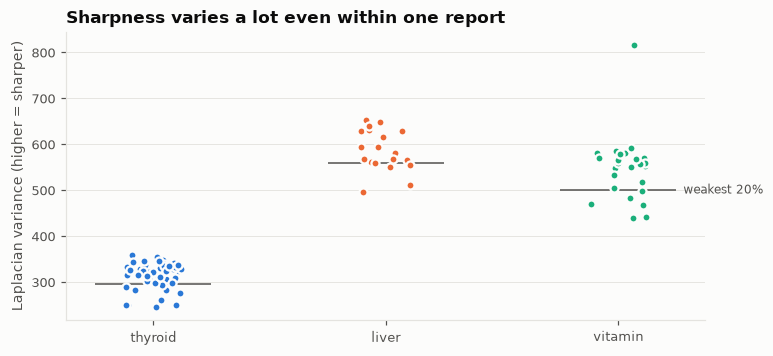

In [7]:
# --- 3.2 Sharpness by layout (one dot per photo) -------------------------------------------
fig, ax = plt.subplots(figsize=(7.5, 3.4))
order = ["thyroid", "liver", "vitamin"]
rng = np.random.default_rng(0)
for i, lay in enumerate(order):
    v = df[df.layout == lay].sharpness
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(v)), v, s=28, color=viz.LAYOUT_COLORS[lay],
               edgecolor=viz.SURFACE, linewidth=1.5, zorder=3)
    ax.hlines(v.quantile(0.2), i - 0.25, i + 0.25, color=viz.MUTED, linewidth=1)   # watch-list line
ax.set_xticks(range(3), order); ax.set_ylabel("Laplacian variance (higher = sharper)")
ax.set_title("Sharpness varies a lot even within one report")
ax.text(2.28, df[df.layout == "vitamin"].sharpness.quantile(0.2), "weakest 20%", fontsize=8, color=viz.MUTED, va="center")
ax.grid(axis="x", visible=False)
fig.savefig(RESULTS / "01_audit" / "sharpness_by_layout.png"); plt.show()

## Part 4 · Near-duplicates and a leakage-safe split
A **perceptual hash** (pHash) is a 64-bit fingerprint of how an image *looks*. Two photos whose fingerprints differ in ≤ 4 bits are near-identical. We link those photos into **groups** (union-find), then assign **whole groups** to train, validation or test. The split is also stratified by layout, so each split contains all three report types.

Target: about 68 / 16 / 16, which gives 74 / 12 / 14 photos: the target was 16 each for validation and test, but whole near-duplicate groups must stay together, so the splits land a little under.

In [8]:
# --- 4.1 Group near-duplicates and split (same code that notebook 02 uses to build YOLO data)
from build_dataset import phash_groups, stratified_group_split, PHASH_MAX_DIST
df["dup_group"] = phash_groups([RAW / f for f in df.file])
n_hold = max(1, round(0.16 * len(df)))      # same holdout rule as tools/build_dataset.py
split = stratified_group_split(df, n_val=n_hold, n_test=n_hold)
print("Near-duplicate groups:", df.dup_group.nunique(), f"(pHash distance <= {PHASH_MAX_DIST})")
print(split.groupby(["layout", "split"]).size().unstack(fill_value=0).to_string())

# Leakage check: every group must sit in exactly ONE split.
spread = split.groupby("dup_group").split.nunique()
assert (spread == 1).all(), "A near-duplicate group is spread across splits!"
print("\nLeakage check passed: every near-duplicate group sits in exactly one split.")

Near-duplicate groups: 32 (pHash distance <= 4)
split    test  train  val
layout                   
liver       3     15    3
thyroid     7     39    5
vitamin     4     20    4

Leakage check passed: every near-duplicate group sits in exactly one split.


In [9]:
# --- 4.2 Compare with the committed split, then save the audit table -----------------------
committed = REPO / "datasets" / "split.csv"
if committed.exists():
    same = pd.read_csv(committed).set_index("file").split.equals(split.set_index("file").split)
    print("Identical to the split used for training:", same)
split.to_csv(RESULTS / "01_audit" / "image_audit.csv", index=False)
split.head()

Identical to the split used for training: True


,file,width,height,ribbon_hue,orientation,layout,sharpness,brightness,contrast,low_sharpness,low_contrast,watch_list,dup_group,split
0,thyrocare_0_1001.jpg,635,1043,165.0,portrait,vitamin,548.906686,189.444982,22.746584,False,False,False,0,train
1,thyrocare_0_1174.jpg,939,631,103.0,landscape,thyroid,260.060072,168.618399,24.190964,True,False,True,1,val
2,thyrocare_0_122.jpg,939,631,104.0,landscape,thyroid,327.611249,167.209379,22.183829,False,False,False,2,train
3,thyrocare_0_123.jpg,939,631,103.0,landscape,thyroid,249.367792,167.204107,23.909535,True,False,True,1,val
4,thyrocare_0_1248.jpg,939,631,103.0,landscape,thyroid,250.300579,167.064926,23.903385,True,False,True,1,val


**Honest caveat:** grouping removes *near-identical* copies, but every split still contains the same three documents. The test score therefore answers *"how well does the pipeline cope with new photos of known report formats?"* It does not answer *"will it read any lab's report?"* Notebook 05 makes this distinction explicit.

## Part 5 · Data dictionary
A data dictionary lists every field: its meaning, type, expected values and known problems. An image project has three "tables" to document.

In [10]:
# --- 5.1 The data dictionary, saved for the report ---------------------------------------
dd = pd.DataFrame([
  # table, field, type, meaning, example, known issue
  ("image_audit", "file", "string", "photo file name", "thyrocare_0_122.jpg", "photo shows patient name -> never publish unredacted"),
  ("image_audit", "layout", "category", "which printed report", "thyroid / liver / vitamin", "only 3 documents exist"),
  ("image_audit", "sharpness", "float", "variance of Laplacian", "higher = sharper", "depends on image size; compare within layout"),
  ("image_audit", "brightness / contrast", "float", "mean / std of grey levels", "0-255", "glare inflates brightness"),
  ("image_audit", "dup_group", "int", "near-duplicate group (pHash <= 4)", "0..N", "threshold is a judgement call"),
  ("image_audit", "split", "category", "train / val / test", "74 / 12 / 14", "small test set -> wide uncertainty"),
  ("yolo_labels", "0 test_name", "box", "name of the lab test", "TOTAL THYROXINE (T4)", "long; can be cut off by the photo edge"),
  ("yolo_labels", "1 value", "box", "measured result", "2.14", "MOST CRITICAL: a decimal error changes the medical meaning"),
  ("yolo_labels", "2 unit", "box", "unit of measurement", "µIU/ml", "µ and l/i are hard for OCR"),
  ("yolo_labels", "3 reference_range", "box", "normal range", "0.3-5.5", "vitamin page: multi-line, printed BELOW the test name"),
  ("output_csv", "image, row", "string, int", "source photo and row number", "-", "-"),
  ("output_csv", "test_name, value, unit, reference_range", "string", "OCR text per field", "-", "value should parse as a number"),
  ("output_csv", "det_conf_min / ocr_conf_min", "float", "lowest YOLO / Tesseract confidence in the row", "0-1 / 0-100", "low -> human review"),
  ("output_csv", "needs_review, review_reason", "bool, string", "row flagged for a human check", "missing:unit", "-"),
], columns=["table", "field", "type", "meaning", "example", "known_issue"])
dd.to_csv(RESULTS / "01_audit" / "data_dictionary.csv", index=False)
pd.set_option("display.max_colwidth", 70)
dd

,table,field,type,meaning,example,known_issue
0,image_audit,file,string,photo file name,thyrocare_0_122.jpg,photo shows patient name -> never publish unredacted
1,image_audit,layout,category,which printed report,thyroid / liver / vitamin,only 3 documents exist
2,image_audit,sharpness,float,variance of Laplacian,higher = sharper,depends on image size; compare within layout
3,image_audit,brightness / contrast,float,mean / std of grey levels,0-255,glare inflates brightness
4,image_audit,dup_group,int,near-duplicate group (pHash <= 4),0..N,threshold is a judgement call
5,image_audit,split,category,train / val / test,74 / 12 / 14,small test set -> wide uncertainty
6,yolo_labels,0 test_name,box,name of the lab test,TOTAL THYROXINE (T4),long; can be cut off by the photo edge
7,yolo_labels,1 value,box,measured result,2.14,MOST CRITICAL: a decimal error changes the medical meaning
8,yolo_labels,2 unit,box,unit of measurement,µIU/ml,µ and l/i are hard for OCR
9,yolo_labels,3 reference_range,box,normal range,0.3-5.5,"vitamin page: multi-line, printed BELOW the test name"


## Summary
- 100 photos = **3 documents** × many capture conditions, a critical finding that shapes the split, the evaluation and the claims we can make.
- Image quality varies a lot even within one document, so the OCR preprocessing must be robust.
- A **leakage-safe, layout-stratified 74/12/14 split** is saved, and every near-duplicate group sits in one split.

**Mentor check (interview practice)**
1. Why can't we split the 100 photos randomly?
2. Why is the image-quality "watch list" computed *within* each layout?
3. An interviewer says: *"Your model only saw three reports, so isn't it overfit?"* What do you answer?

**Next → Notebook 02:** draw the field boxes and convert them to YOLO format.